In [ ]:
import time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import ReduceLROnPlateau

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

from google.colab import drive
drive.mount('/content/drive')

df_raw = pd.read_csv('/content/drive/MyDrive/pbl-ml/diabetes_binary_5050split_health_indicators_BRFSS2015.csv')
LABEL = 'Diabetes_binary'
print("Ukuran data:", df_raw.shape)

Mounted at /content/drive
Ukuran data: (70692, 22)


In [ ]:
FITUR_DIBUANG = ['Income', 'CholCheck', 'HvyAlcoholConsump',
                 'AnyHealthcare', 'NoDocbcCost', 'Education']

df = df_raw.drop(columns=FITUR_DIBUANG)
df = df.drop_duplicates().reset_index(drop=True)
df = df.astype({c: "int64" for c in df.columns if c != "BMI"})
df["BMI"] = df["BMI"].astype(float)

X = df.drop(columns=[LABEL])
y = df[LABEL]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

# Clip outlier BMI (batas IQR dari train saja)
q1, q3 = X_train["BMI"].quantile([0.25, 0.75])
iqr = q3 - q1
BMI_LOW, BMI_HIGH = q1 - 1.5 * iqr, q3 + 1.5 * iqr
X_train["BMI"] = X_train["BMI"].clip(BMI_LOW, BMI_HIGH)
X_test["BMI"] = X_test["BMI"].clip(BMI_LOW, BMI_HIGH)

# Scaling (fit hanya di train)
num_cols = ["BMI", "Age", "GenHlth", "MentHlth", "PhysHlth"]
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

X_tr = X_train_scaled.values.astype("float32")
X_te = X_test_scaled.values.astype("float32")
y_tr = y_train.values.astype("float32")
y_te = y_test.values.astype("float32")

print("Train:", X_tr.shape, "| Test:", X_te.shape)

Train: (50557, 15) | Test: (12640, 15)


In [ ]:
BEST_PARAMS = {
    "units1": 64, "units2": 32, "units3": 16,
    "dropout": 0.4, "lr": 0.001, "batch_size": 128, "l2": 0.001,
}
EPOCHS = 40
THRESHOLD = 0.45   # sebelumnya 0.5

def bangun_ann(p, n_fitur):
    reg = regularizers.l2(p["l2"]) if p["l2"] > 0 else None
    m = keras.Sequential([
        layers.Input(shape=(n_fitur,)),
        layers.Dense(p["units1"], activation="relu", kernel_regularizer=reg),
        layers.BatchNormalization(),
        layers.Dropout(p["dropout"]),
        layers.Dense(p["units2"], activation="relu", kernel_regularizer=reg),
        layers.BatchNormalization(),
        layers.Dropout(p["dropout"]),
        layers.Dense(p["units3"], activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=p["lr"]),
              loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return m

tf.keras.backend.clear_session()
tf.random.set_seed(SEED)
ann = bangun_ann(BEST_PARAMS, X_tr.shape[1])
ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,033 (15.75 KB)

 Trainable params: 3,841 (15.00 KB)

 Non-trainable params: 192 (768.00 B)

In [ ]:
t0 = time.perf_counter()
history = ann.fit(
    X_tr, y_tr,
    epochs=EPOCHS,
    batch_size=BEST_PARAMS["batch_size"],
    callbacks=[ReduceLROnPlateau(monitor="loss", factor=0.5, patience=3, min_lr=1e-5)],
    verbose=0
)
waktu_train = time.perf_counter() - t0
print(f"Waktu training: {waktu_train:.1f} detik")

Waktu training: 52.8 detik


,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,TN,FP,FN,TP
0,0.50,0.7363,0.7286,0.7963,0.7610,0.8094,4001,1976,1357,5306
1,0.45,0.7392,0.7138,0.8436,0.7733,0.8094,3723,2254,1042,5621



Classification report (threshold = 0.45):
                precision    recall  f1-score   support

Tidak diabetes     0.7813    0.6229    0.6932      5977
      Diabetes     0.7138    0.8436    0.7733      6663

      accuracy                         0.7392     12640
     macro avg     0.7475    0.7333    0.7332     12640
  weighted avg     0.7457    0.7392    0.7354     12640



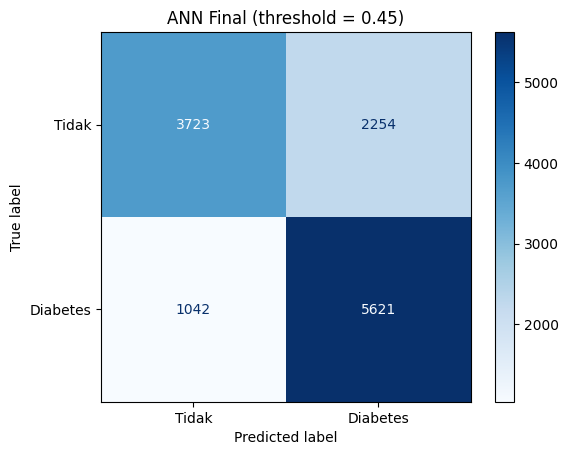

In [ ]:
y_prob = ann.predict(X_te, verbose=0).ravel()

def evaluasi_threshold(th):
    y_pred = (y_prob >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, y_pred, labels=[0, 1]).ravel()
    return {
        "Threshold": th,
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred),
        "Recall": recall_score(y_te, y_pred),
        "F1-Score": f1_score(y_te, y_pred),
        "ROC-AUC": roc_auc_score(y_te, y_prob),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }

banding_th = pd.DataFrame([evaluasi_threshold(0.5), evaluasi_threshold(THRESHOLD)])
display(banding_th.round(4))

y_pred = (y_prob >= THRESHOLD).astype(int)
print(f"\nClassification report (threshold = {THRESHOLD}):")
print(classification_report(y_te, y_pred, target_names=["Tidak diabetes", "Diabetes"], digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred, labels=[0, 1]),
                       display_labels=["Tidak", "Diabetes"]).plot(cmap="Blues", values_format="d")
plt.title(f"ANN Final (threshold = {THRESHOLD})")
plt.show()

In [ ]:
OUT = "/content/drive/MyDrive/pbl-ml/model-final/"
import os; os.makedirs(OUT, exist_ok=True)

ann.save(OUT + "ann_glucosafe.keras")
joblib.dump(scaler, OUT + "scaler.pkl")

config = {
    "threshold": THRESHOLD,
    "fitur_urut": list(X_train.columns),   # urutan kolom harus sama saat prediksi
    "num_cols": num_cols,
    "bmi_clip": [float(BMI_LOW), float(BMI_HIGH)],
    "best_params": BEST_PARAMS, "epochs": EPOCHS,
}
with open(OUT + "config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Tersimpan di:", OUT)

Tersimpan di: /content/drive/MyDrive/pbl-ml/model-final/
